In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.home() / "projects" / "loan-default-risk"
df = pd.read_csv(root / "data" / "raw" / "accepted_2007_to_2018Q4.csv.gz", low_memory=False)
print(df.shape)
df.head()

(2260701, 151)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df["loan_status"].value_counts(dropna=False)

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
NaN                                                         33
Name: count, dtype: int64

(1345310, 152)
target
0    1076751
1     268559
Name: count, dtype: int64
target
0    0.8004
1    0.1996
Name: proportion, dtype: float64


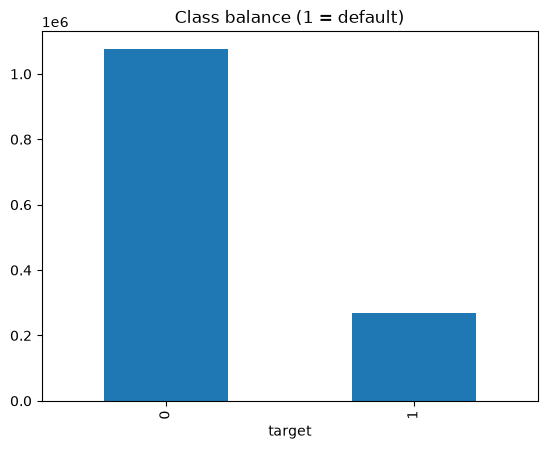

In [5]:
done = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
done["target"] = (done["loan_status"] == "Charged Off").astype(int)
print(done.shape)
print(done["target"].value_counts())
print(done["target"].value_counts(normalize=True).round(4))
done["target"].value_counts().plot(kind="bar", title="Class balance (1 = default)")
plt.show()

In [6]:
miss = (done.isna().mean() * 100).sort_values(ascending=False)
print((miss > 50).sum(), "columns with more than 50% missing")
miss.head(30)

58 columns with more than 50% missing


member_id                                     100.000000
next_pymnt_d                                  100.000000
orig_projected_additional_accrued_interest     99.720585
hardship_amount                                99.572292
hardship_last_payment_amount                   99.572292
hardship_length                                99.572292
hardship_status                                99.572292
hardship_reason                                99.572292
deferral_term                                  99.572292
hardship_start_date                            99.572292
hardship_end_date                              99.572292
hardship_type                                  99.572292
hardship_loan_status                           99.572292
hardship_payoff_balance_amount                 99.572292
hardship_dpd                                   99.572292
payment_plan_start_date                        99.572292
sec_app_mths_since_last_major_derog            99.506062
sec_app_revol_util             

In [7]:
done["issue_year"] = pd.to_datetime(done["issue_d"], format="%b-%Y").dt.year
print(done.groupby("issue_year")["target"].agg(["count", "mean"]).round(4))

             count    mean
issue_year                
2007           251  0.1793
2008          1562  0.1581
2009          4716  0.1260
2010         11536  0.1289
2011         21721  0.1518
2012         53367  0.1620
2013        134804  0.1560
2014        223102  0.1845
2015        375545  0.2018
2016        293095  0.2328
2017        169300  0.2312
2018         56311  0.1575


In [10]:
(root / "data" / "processed").mkdir(parents=True, exist_ok=True)
done.to_parquet(root / "data" / "processed" / "loans_resolved.parquet", index=False)
print("saved", done.shape)

saved (1345310, 153)
